In [8]:
import os
import json
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

COLS = ["Time (s)", "Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)", "Trigger", "Mode"]
CACHE_VERSION = 1
# 快取檔：欄位 -> (檔名, dtype)
CACHE_FILES = {"Time (s)": ("time.bin", np.float64), "Pressure (cmH2O)": ("pressure.bin", np.float64),
               "Flow (L/min)": ("flow.bin", np.float64), "Volume (mL)": ("volume.bin", np.float64),
               "Trigger": ("trigger.bin", np.int8), "Mode": ("mode.bin", np.int16)}

def load(csv_path, cache_dir=None):
    """
    讀入錄製檔，回傳「輕量版」DataFrame（Time (s), Trigger, Mode），one row -> one sample point（100 Hz）
    - 和原版一樣：Mode 去掉前後空白、丟掉 Pressure 是空值的列
    - Trigger 存 int8（0/1）、Mode 存 category，每列約 10 bytes（原本約 48 bytes），1.5GB 的 gz 約 2.4 GB
    - P/F/V 不放記憶體，第一次讀檔時寫到 cache_dir（預設在錄製檔旁的「檔名_cache」資料夾），
      cut_breaths 再從那裡取；同一個錄製檔第二次 load 會直接讀快取，不用重新解析 CSV
    """
    if cache_dir is None:
        cache_dir = os.path.splitext(csv_path)[0] + "_cache"
    src = os.stat(csv_path)
    meta_path = os.path.join(cache_dir, "meta.json")
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, encoding="utf-8") as f:
            meta = json.load(f)
        if (meta.get("version"), meta.get("size"), meta.get("mtime")) != (CACHE_VERSION, src.st_size, src.st_mtime):
            meta = None                                            # 錄製檔換過或快取格式不同 -> 重建
    if meta is None:
        meta = _build_cache(csv_path, cache_dir)
        meta.update(version=CACHE_VERSION, size=src.st_size, mtime=src.st_mtime)
        with open(meta_path, "w", encoding="utf-8") as f:          # 最後才寫 meta，中斷的快取不會被當成完整的
            json.dump(meta, f, ensure_ascii=False)

    read = lambda c: np.fromfile(os.path.join(cache_dir, CACHE_FILES[c][0]), CACHE_FILES[c][1])
    mode = pd.Categorical.from_codes(read("Mode"), categories=meta["modes"])
    wave = pd.DataFrame({"Time (s)": read("Time (s)"), "Trigger": read("Trigger"), "Mode": mode}, copy=False)
    wave.attrs["cache_dir"] = cache_dir                            # 給 cut_breaths 找波形用
    return wave


def _iter_batches(csv_path, block=32 << 20, workers=min(8, os.cpu_count() or 1)):
    """
    解壓後按「整行」切成 block，丟給多個執行緒平行解析，再照原順序一塊塊吐出
    （pyarrow 的串流讀取是單執行緒，太慢；同時在處理的 block 有上限，記憶體不會爆）
    """
    stream = pa.input_stream(csv_path, compression="gzip" if csv_path.endswith(".gz") else None)
    head = stream.read(1 << 16)                                    # 標頭在第一行
    nl = head.index(b"\n") + 1
    names = head[:nl].decode("utf-8-sig").rstrip("\r\n").split(",")
    types = {c: pa.float64() for c in COLS}
    types["Mode"] = pa.string()
    ropt = pacsv.ReadOptions(column_names=names, use_threads=False, block_size=block * 2)
    copt = pacsv.ConvertOptions(include_columns=COLS, column_types=types,
                                strings_can_be_null=True)          # 空字串當空值，同 pandas
    parse = lambda buf: pacsv.read_csv(pa.py_buffer(buf), read_options=ropt, convert_options=copt)

    pending, rest = deque(), head[nl:]
    with ThreadPoolExecutor(workers) as pool:
        while True:
            data = stream.read(block)
            buf = rest + data
            cut = len(buf) if not data else buf.rfind(b"\n") + 1   # 檔尾就整塊送出
            rest = buf[cut:]
            if cut:
                pending.append(pool.submit(parse, buf[:cut]))
            while pending and (len(pending) > workers + 2 or not data):
                yield from pending.popleft().result().to_batches()
            if not data:
                break


def _build_cache(csv_path, cache_dir):
    """平行解析錄製檔，邊讀邊寫成二進位快取，記憶體只用到幾個 block"""
    os.makedirs(cache_dir, exist_ok=True)
    meta_path = os.path.join(cache_dir, "meta.json")
    if os.path.exists(meta_path):
        os.remove(meta_path)
    cats = {}                                                      # 模式字串 -> category 編號
    files = {c: open(os.path.join(cache_dir, name), "wb") for c, (name, _) in CACHE_FILES.items()}
    try:
        for batch in _iter_batches(csv_path):
            batch = batch.filter(pc.is_valid(batch.column("Pressure (cmH2O)")))   # 同原版 dropna(subset=Pressure)
            for c in COLS[:4]:
                batch.column(c).to_numpy(zero_copy_only=False).astype(np.float64).tofile(files[c])
            trig = pc.fill_null(pc.equal(batch.column("Trigger"), 1.0), False)
            trig.to_numpy(zero_copy_only=False).astype(np.int8).tofile(files["Trigger"])
            # Mode：去掉前後空白後編成整數，-1 = 這列沒有 Mode
            enc = pc.utf8_trim_whitespace(batch.column("Mode")).dictionary_encode()
            lut = np.array([cats.setdefault(v, len(cats)) for v in enc.dictionary.to_pylist()] + [-1], np.int16)
            idx = pc.fill_null(enc.indices, -1).to_numpy(zero_copy_only=False)
            lut[idx].tofile(files["Mode"])
    finally:
        for f in files.values():
            f.close()
    return {"source": os.path.abspath(csv_path), "modes": list(cats)}


def mode_segments(wave, latency=1.5):
    """
    找出每段模式的時間範圍，回傳DataFrame：mode, start_time, end_time，範圍為 [start, end]
    - start_time：PSV沒有 trigger，取舊模式最後一次出現前最大延遲秒數內的trigger
    - end_time  ：取舊模式最後一次出現到新模式第一次出現之間最新的trigger
    """
    t = wave["Time (s)"].to_numpy()                                # 所有時間
    trig_t = t[wave["Trigger"].to_numpy() == 1]                    # 所有trigger的時間
    polls = wave.dropna(subset=["Mode"])                           # 只留下有Mode值的row
    pt, pm = polls["Time (s)"].to_numpy(), polls["Mode"].to_numpy()

    # 第一段從檔案開頭開始
    starts, modes = [t[0]], [pm[0]]

    # k = Mode 值和前一筆不同的位置（模式切換）
    for k in np.flatnonzero(pm[1:] != pm[:-1]) + 1:
        tA, tB = pt[k - 1], pt[k]                                  # tA:最後一次舊模式, tB:第一次新模式
        new = trig_t[(trig_t > tA) & (trig_t <= tB)]               # tA~tB之間的trigger
        old = trig_t[(trig_t <= tA) & (trig_t >= tA - latency)]    # tA為這個trigger的回應
        if len(new):
            b = new[-1]                                            # 最新的trigger(end_time)
        elif len(old):
            b = old[-1]                                            # 前一口trigger(start_time)
        else:
            b = tA                                                 # 兩邊都沒trigger，只能用tA
        starts.append(max(b, starts[-1]))                          # 不讓切換點早於前一段起點
        modes.append(pm[k])

    # 每段的結束 = 下一段的開始；最後一段到檔案結尾
    segs = pd.DataFrame({"mode": modes, "start_time": starts})
    segs["end_time"] = segs["start_time"].shift(-1).fillna(t[-1] + 0.01)
    # 拿掉長度為0的區間
    return segs[segs["end_time"] > segs["start_time"]].reset_index(drop=True)




SPONT_LABEL = "SPN-CPAP*"                    # SPN-CPAP但 Mode 未回報
MAX_GAP = 300                                # 秒，最大等待時間
def fill_spont_gaps(wave, segs, max_gap=MAX_GAP):
    """
    因為一號病人錄製檔前半段，在PSV期間沒有加入固定時間輪詢，所以才要這個function...
    若 PC區間內trigger間隔 > max_gap：插入SPONT區間 [前一個 trigger, 下一個 trigger)
    """
    t = wave["Time (s)"].to_numpy()
    trig_t = t[wave["Trigger"].to_numpy() == 1]
    rows = segs.to_dict("records")
    for i in np.flatnonzero(np.diff(trig_t) > max_gap):
        a, b = trig_t[i], trig_t[i + 1]
        for k, s in enumerate(rows):
            if s["start_time"] <= a and b <= s["end_time"] and not s["mode"].startswith("SPN-CPAP"):
                rows[k:k + 1] = [dict(s, end_time=a),
                                 dict(mode=SPONT_LABEL, start_time=a, end_time=b),
                                 dict(s, start_time=b)]
                break
    out = pd.DataFrame(rows)
    return out[out["end_time"] > out["start_time"]].reset_index(drop=True)


def find_breaths(wave, segs):
    """
    用 trigger 切呼吸，回傳DataFrame：breath_id, mode, boundary, start_time, end_time
    - 每兩個相鄰 trigger 之間是一口，不跨模式另切，所以模式切換處不會少一口
    - breath_id：起點是整個錄製檔第幾個 trigger（從1開始）
    - mode     ：起點落在哪一段模式區間（SPN-CPAP 段沒有 trigger，整段就是一口）
    - boundary ：模式切換前後各一口，可能混到前後模式，訓練時篩掉（編號照留，不影響其他口）
    - end_time ：是該口最後一個點的時間
    - 第一個 trigger 之前、最後一個 trigger 之後不是完整的一口，不列入
    """
    t = wave["Time (s)"].to_numpy()
    idx = np.flatnonzero(wave["Trigger"].to_numpy() == 1)         # 所有 trigger 的列
    starts, ends = t[idx[:-1]], t[idx[1:] - 1]                     # 相鄰兩個 trigger 為一口
    seg = np.maximum(np.searchsorted(segs["start_time"].to_numpy(), starts, side="right") - 1, 0)
    change = seg[1:] != seg[:-1]                                   # 這口和下一口在不同段
    boundary = np.zeros(len(seg), bool)
    boundary[:-1] |= change                                        # 切換前最後一口
    boundary[1:] |= change                                         # 切換後第一口
    return pd.DataFrame({"breath_id": np.arange(1, len(starts) + 1),
                         "mode": segs["mode"].to_numpy()[seg], "boundary": boundary,
                         "start_time": starts, "end_time": ends})


def cut_breaths(wave, breaths):
    """
    依breaths每口的起訖時間，從wave剪出波形

    回傳 BreathWaves（用法和 dict 一樣）：{breath_id: 該口波形 DataFrame}
      - 欄位：Time (s), Pressure, Flow, Volume
      - 列號從 0 重新編，Time (s) 保留原錄製檔時間
      - 波形留在 load() 的快取檔裡，取用某一口時才讀那一口，不會整包塞進記憶體
    """
    t = wave["Time (s)"].to_numpy()
    # 用二分搜尋一次找出所有口的起訖列號，不用每口掃整個檔
    # ±1e-9 是容差，避免浮點誤差漏掉起點或終點那一列
    s = np.searchsorted(t, breaths["start_time"].to_numpy() - 1e-9)                 # 起點列
    e = np.searchsorted(t, breaths["end_time"].to_numpy() + 1e-9, side="right")     # 終點列的下一列
    return BreathWaves(wave.attrs["cache_dir"], breaths["breath_id"].to_numpy(), s, np.maximum(e, s))


class BreathWaves(Mapping):
    """
    放在硬碟快取上的呼吸波形，用法和 dict 一樣：
      waves[breath_id]、list(waves)、len(waves)、for bid in waves、waves.items()
    """
    def __init__(self, cache_dir, ids, starts, ends):
        self.ids, self.starts, self.ends = ids, starts, ends
        self._pos = {int(b): k for k, b in enumerate(ids)}
        self._data = {c: np.memmap(os.path.join(cache_dir, name), dt, mode="r")
                      for c, (name, dt) in CACHE_FILES.items() if c in COLS[:4]}

    def __getitem__(self, bid):
        k = self._pos[bid]
        a, b = self.starts[k], self.ends[k]
        return pd.DataFrame({c: np.array(v[a:b]) for c, v in self._data.items()})

    def __iter__(self):
        return (int(b) for b in self.ids)

    def __len__(self):
        return len(self.ids)

# 切分設定

In [11]:
path = r"D:\downloads"                           # 錄製檔存放資料夾位置
REC = "1.gz"      # 錄製檔名稱
OUTPUT_MODES = {"PC-AC"}                         # PC-AC、VC-AC、SPN-CPAP

In [13]:
# 根據mode切分每個mode的區間
wave = load(os.path.join(path, REC))
segs = fill_spont_gaps(wave, mode_segments(wave))
print(segs)
print("----------------------------------")

# 利用trigger切分呼吸
breaths = find_breaths(wave, segs)
print(breaths["mode"].value_counts())
print("----------------------------------")

# 利用OUTPUT_MODES篩出目標呼吸，並製作成waves，格式為<dict>
target_mode_breaths = breaths[breaths["mode"].isin(OUTPUT_MODES)]
waves = cut_breaths(wave, target_mode_breaths)
print(f"輸出 {len(waves)} 口：{sorted(OUTPUT_MODES)}")
print("----------------------------------")

        mode  start_time   end_time
0      PC-AC        0.00   28331.53
1  SPN-CPAP*    28331.53   36725.20
2      PC-AC    36725.20  114998.15
3   SPN-CPAP   114998.15  131334.19
4      PC-AC   131334.19  476612.11
5  SPN-CPAP*   476612.11  516773.00
6      PC-AC   516773.00  566599.60
7   SPN-CPAP   566599.60  625297.53
8   SPN-CPAP   625297.53  730204.91
----------------------------------
mode
PC-AC        131290
SPN-CPAP*         2
SPN-CPAP          2
Name: count, dtype: int64
----------------------------------
輸出 131290 口：['PC-AC']
----------------------------------


# 後續可任意處理

In [17]:
# 列出waves前10口，此時的編號為原始錄製檔的編號
print(list(waves)[:30])

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


In [19]:
waves[1188]

,Time (s),Pressure (cmH2O),Flow (L/min),Volume (mL)
0,4981.15,7.5,2.2,1.4
1,4981.16,7.4,3.8,2.7
2,4981.17,7.6,5.9,5.4
3,4981.18,7.9,7.2,6.8
4,4981.19,8.3,8.4,9.5
...,...,...,...,...
376,4984.91,9.0,-5.4,91.8
377,4984.92,8.9,-4.8,91.8
378,4984.93,8.8,-4.5,91.8
379,4984.94,8.6,-3.6,90.5


# 分析

In [22]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft, fftfreq, ifft

In [23]:
fs = 100  # 取樣率 Hz(0.01 s 一點)

def fft_mag(x, fs=fs, nfft=4096):
    x = x - x.mean()                 # 去 DC
    x = x * np.hanning(len(x))       # 視窗
    spec = np.abs(np.fft.rfft(x, n=nfft)) / len(x)
    freq = np.fft.rfftfreq(nfft, 1 / fs)
    return freq, spec

def plot_breath_fft(breaths, bid, fmax=10):
    b = breaths[bid]
    t = b["Time (s)"].values - b["Time (s)"].values[0]   # 呼吸內從 0 秒開始
    sigs = {
        "Pressure (cmH2O)": b["Pressure (cmH2O)"].values,
        "Flow (L/min)":     b["Flow (L/min)"].values,
        "Volume (mL)":      b["Volume (mL)"].values,
    }
    fig, ax = plt.subplots(3, 2, figsize=(8, 4))
    for i, (name, x) in enumerate(sigs.items()):
        freq, spec = fft_mag(x)
        ax[i, 0].plot(t, x)
        ax[i, 0].set_ylabel(name)
        ax[i, 1].plot(freq, spec)
        ax[i, 1].set_xlim(0, fmax)
    ax[0, 0].set_title(f"Breath {bid}: time domain")
    ax[0, 1].set_title("FFT magnitude")
    ax[-1, 0].set_xlabel("Time (s)")
    ax[-1, 1].set_xlabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()

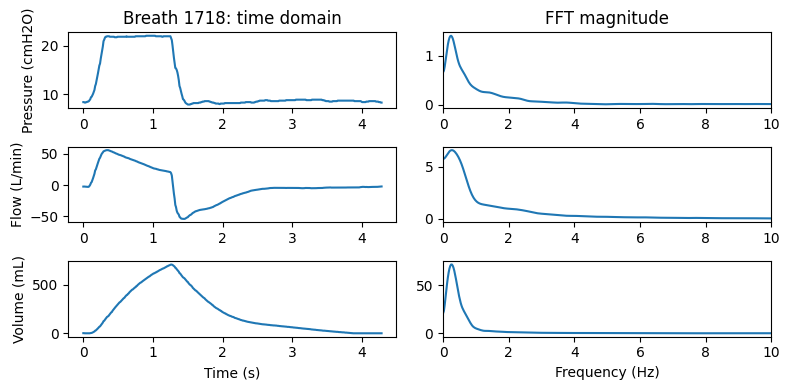

In [26]:
# normal breath
plot_breath_fft(waves, 1718)

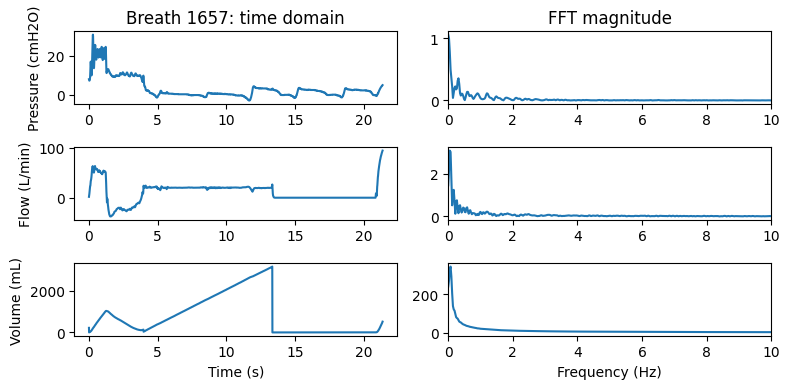

In [28]:
# tube Disconnect
plot_breath_fft(waves, 1657)

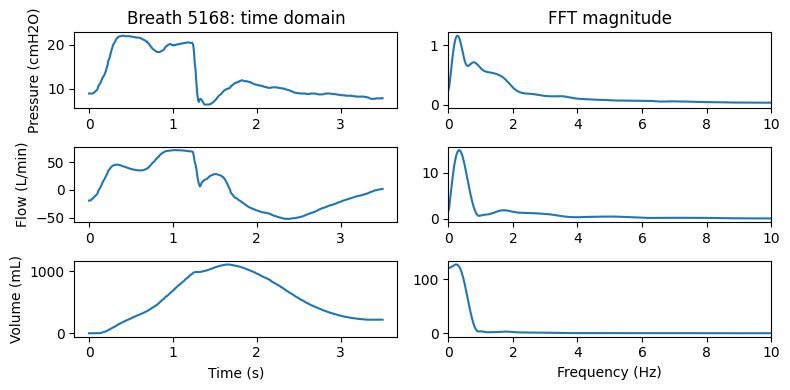

In [30]:
# Insufficient inspiratory flow
plot_breath_fft(waves, 5168)

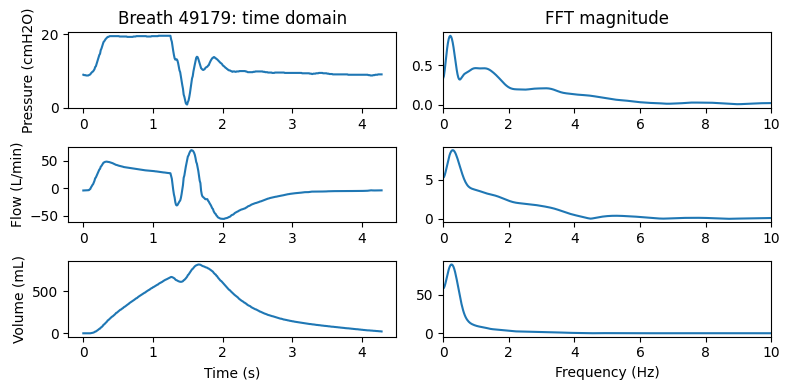

In [36]:
# Ineffective trigger
plot_breath_fft(waves, 49179)

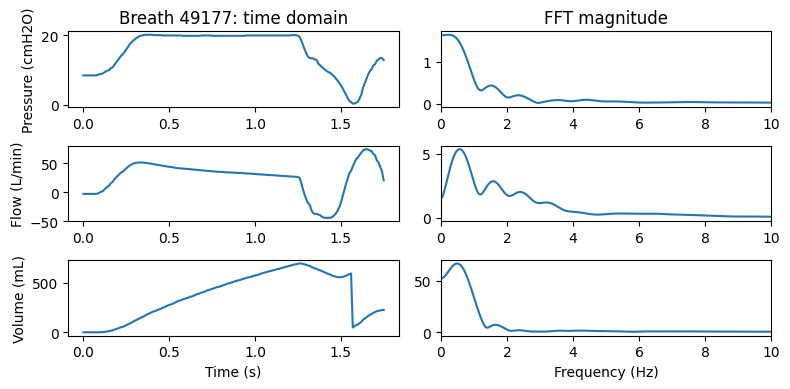

In [38]:
# Double trigger
plot_breath_fft(waves, 49177)

In [40]:
import numpy as np, pywt
import matplotlib.pyplot as plt

fs = 100
wavelet = "cmor1.5-1.0"                    # 複數 Morlet,適合看時頻能量
freqs = np.linspace(0.15, 15, 100)          # 想看的頻率範圍 (Hz)
scales = pywt.central_frequency(wavelet) * fs / freqs   # 頻率換成 scale

def plot_breath_cwt(breaths, bid, vmax_pct=99):
    b = breaths[bid]
    tt = b["Time (s)"].values - b["Time (s)"].values[0]
    fig, ax = plt.subplots(3, 2, figsize=(8, 4))
    for i, name in enumerate(["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]):
        x = b[name].values
        coef, f = pywt.cwt(x - x.mean(), scales, wavelet, sampling_period=1/fs)
        mag = np.abs(coef)
        ax[i, 0].plot(tt, x); ax[i, 0].set_ylabel(name)
        ax[i, 1].pcolormesh(tt, f, mag, shading="auto", cmap="viridis",
                            vmax=np.percentile(mag, vmax_pct))   # 避免低頻把顏色壓扁
        ax[i, 1].set_ylabel("Hz")
    ax[-1, 0].set_xlabel("Time (s)"); ax[-1, 1].set_xlabel("Time (s)")
    plt.tight_layout(); plt.show()

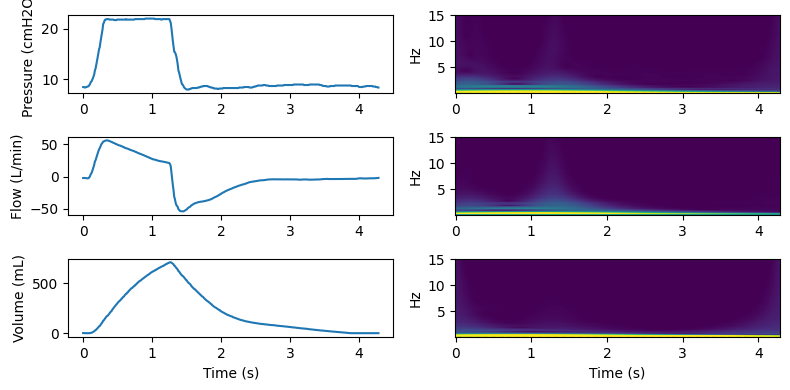

In [42]:
# normal breath
plot_breath_cwt(waves, 1718)

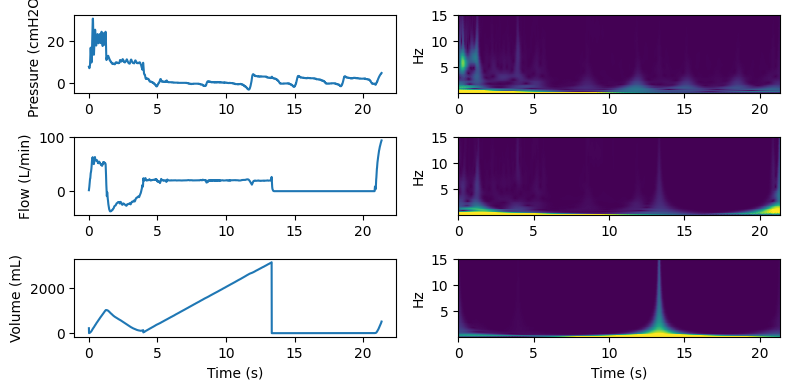

In [43]:
# tube Disconnect
plot_breath_cwt(waves, 1657)

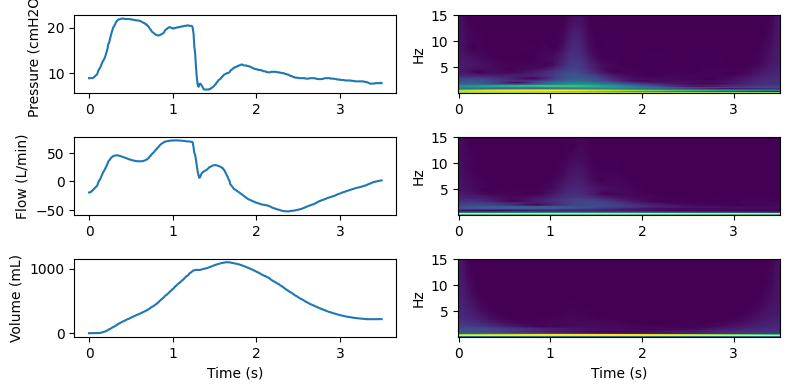

In [44]:
# Insufficient inspiratory flow
plot_breath_cwt(waves, 5168)

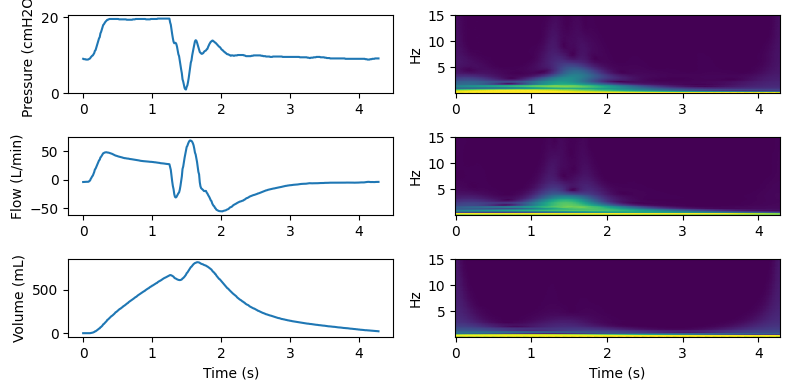

In [46]:
# Ineffective trigger
plot_breath_cwt(waves, 49179)

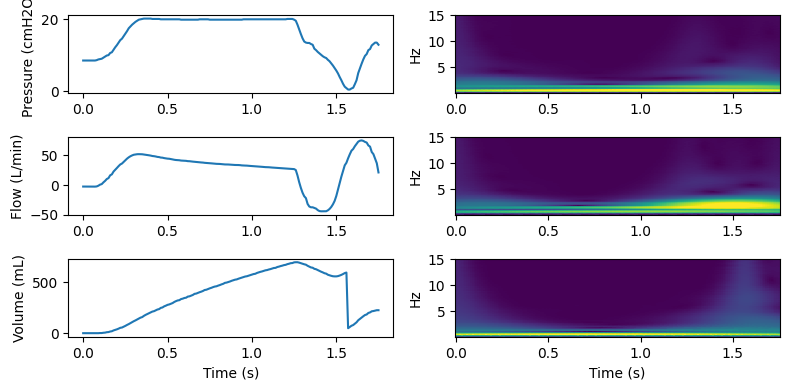

In [48]:
# Double trigger
plot_breath_cwt(waves, 49177)